# Algorithms

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/SIMIND-Jaszak")
datasets.fetch("SPECT/Lu177-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/SIMIND-Jaszak")

SPECT/SIMIND-Jaszak: already downloaded


SPECT/Lu177-NEMA-SymT2: already downloaded


In [2]:
import os
import matplotlib.pyplot as plt
import torch
import pytomography
from pytomography import io
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.algorithms import OSEM, OSMAPOSL, BSREM, KEM
from pytomography.priors import RelativeDifferencePrior
from pytomography.priors import TopNAnatomyNeighbourWeight
from pytomography.transforms.shared import KEMTransform
from pytomography.projectors.shared import KEMSystemMatrix

In [3]:
# Paths are set in the data cell at the top of this tutorial
PATH = DATA / 'SPECT'

In [4]:
# Memory: this tutorial peaks at about 7 GB of RAM, during KEM, whose kernel (1 GB) is built on the CPU, a chunk of
# voxels at a time, and then kept on the GPU, which on Windows counts as RAM too. Each reconstruction prints its estimate
# before it runs (estimate_memory): about 4.4 GB for OSEM, most of it PyTorch and CUDA themselves, and 6 GB for KEM.
# RAM_GB changes nothing here: SPECT reconstructions this size never need to split their work. kernel_on_gpu=False
# keeps KEM's kernel in RAM instead of GPU memory, three times slower.
RAM_GB = 25
pytomography.set_memory_budget(RAM_GB)

The code below is a summary of the SIMIND/DICOM introduciton tutorials. You can select whether or not to explore the SIMIND/DICOM data here

* This demonstrates what kind of code is reusable whether or not you're reconstructing SIMIND or DICOM data

In [5]:
TYPE = 'DICOM' # DICOM or SIMIND

In [6]:
if TYPE=='SIMIND':
    data_path = os.path.join(PATH, 'SIMIND-Jaszak', 'lu177_SYME_jaszak')
    IDX_AXIAL = 64 # for plotting
    # the 208 keV photopeak (tot_w1) and its scatter windows (tot_w2, tot_w3): the energy of amap.hct
    headers = [os.path.join(data_path, f'tot_w{i}.h00') for i in (1, 2, 3)]
    projections, object_meta, proj_meta = io.SPECT.read_simind(headers)
    activity = 1000 # MBq
    time_per_proj = 15 # s
    projections = torch.poisson(projections * activity * time_per_proj)
    photopeak = projections[0]
    scatter = io.SPECT.energy_window_scatter(projections, proj_meta, peak=0, lower=1, upper=2)
    amap = io.attenuation_map(os.path.join(data_path, 'amap.hct'), object_meta,
                              energy_keV=proj_meta.energy_windows[0].photon_keV, layout='mu')
    psf_meta = io.SPECT.simind_psf(headers[0])
elif TYPE=='DICOM':
    data_path = os.path.join(PATH, 'Lu177-NEMA-SymT2')
    IDX_AXIAL = 61 # for plotting
    path_CT = os.path.join(data_path, 'CT')
    files_CT = [os.path.join(path_CT, file) for file in os.listdir(path_CT)]
    file_NM = os.path.join(data_path, 'projection_data.dcm')
    projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
    photopeak = projections[0]  # the 208 keV window
    scatter = io.SPECT.energy_window_scatter(projections, proj_meta, peak=0, lower=1, upper=2)
    amap = io.attenuation_map(files_CT, object_meta, energy_keV=proj_meta.energy_windows[0].photon_keV)
    psf_meta = io.SPECT.collimator_psf('SY-ME', proj_meta.energy_windows[0].photon_keV, intrinsic_fwhm_mm=3.8)
att_transform = SPECTAttenuationTransform(amap)
psf_transform = SPECTPSFTransform(psf_meta)

system_matrix = SPECTSystemMatrix(
    obj2obj_transforms = [att_transform,psf_transform],
    proj2proj_transforms = [],
    object_meta = object_meta,
    proj_meta = proj_meta
)
likelihood = PoissonLogLikelihood(
    system_matrix = system_matrix,
    projections = photopeak,
    additive_term = scatter
)

## Reconstruction Algorithms

With the likelihood established, we can now reconstruct our data. This tutorial will focus on ordered-subset preconditioned gradient ascent algorithms, which all have the form

$$\hat{f}^{n+1} = \hat{f}^{n} + C^{n}(\hat{f}^{n}) \left[\nabla_{f} L(g|f^{n}) - \beta \nabla_{f} V \right] $$

* $\hat{f}^{n}$ is the object estimate of the nth iteration
* $C^{n}(\hat{f}^{n})$ is the preconditioner, which can depend on the current image estimate $\hat{f}$
* $\nabla_{f} L(g|\hat{f}^{n})$ is the gradient of the likelihood function
* $\nabla_{f} V$ is the gradient of some additional penalization or prior function, and $\beta$ is a scaling factor.

### 4.1 OSEM

The ordered-subset expectation maximum algorithm (OSEM) in SPECT imaging corresponds to

* $C^{n}(\hat{f}^{n}) = \hat{f}^{n} / H^T 1$
* $\nabla_{f} L(g|f^{n}) = H^T \left(\frac{g}{H \hat{f}^{n} + s}-H^T 1\right)$ -> this is because of Poisson statistics
* $V=0$

so the reconstruction algorithm can be written as

$$\hat{f}^{n} = \left[\frac{1}{H^T 1} H^T \left(\frac{g}{H\hat{f}^{n}+s}\right)\right] \hat{f}^{n}$$

To reconstruct with OSEM, we first create the reconstruction algorithm, then specify the number of iterations/subsets required for reconstruction. Before it runs, `estimate_memory` says how much RAM and GPU memory it will need with those subsets.

In [7]:
recon_algorithm = OSEM(likelihood)
print(recon_algorithm.estimate_memory(n_subsets=8))
recon_OSEM = recon_algorithm(n_iters = 4, n_subsets = 8)

OSEM (SPECTSystemMatrix): 8 subsets, memory budget 25 GB
Peak ~ 4.4 GB RAM, 0.5 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.2 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, projections (the data) 0.04 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.8 GB RAM, 0.1 GB GPU (Python, PyTorch and CUDA 3.7 RAM, PyTorch's GPU cache (rounded and kept blocks) 0.1 GPU, memory the allocators keep (Windows) 0.1 RAM)
To use less: 4 subsets ~ 4.3 GB RAM, 0.5 GB GPU
(plus whatever else your script keeps)


### 4.2 OSMAPOSL

The ordered subset maximum a posteriori one step late (OSMAPOSL) algorithm is an extension of OSEM that encorporates a prior function $V$

* $C^{n}(\hat{f}^{n}) = \frac{\hat{f}^{n}}{H^T 1 + \beta \nabla_{f^{n}} V}$
* $\nabla_{f^{n}} L(g|f^{n}) = H^T \left(\frac{g}{H \hat{f}^{n} + s}-H^T 1\right)$ -> this is because of Poisson statistics

Thus the algorithm can be written as

$$\hat{f}^{n} = \left[\frac{1}{H^T 1  + \beta \nabla_{f} V} H^T \left(\frac{g}{H\hat{f}^{n}+s}\right)\right] \hat{f}^{n} $$

The user need to provide the smoothing function $V$. In this case, we'll use a relative difference penalty for each voxel that only includes contributing terms from the 8 nearest neighbours based on the anatomical image.

* `beta` (which is $\beta$ above) is the scaling factor for the prior
* `gamma` is a hyperparameter for the relative difference prior.

In [8]:
weight_top8anatomy = TopNAnatomyNeighbourWeight(amap, N_neighbours=8)
prior_rdpap = RelativeDifferencePrior(beta=0.3, gamma=2, weight=weight_top8anatomy)
# to use all nearest neighbours (non attenuation map based) use the code below:
# prior_rdp = RelativeDifferencePrior(beta=0.3, gamma=2)
recon_algorithm_osmaposl = OSMAPOSL(
    likelihood = likelihood,
    prior = prior_rdpap)
recon_osmaposl = recon_algorithm_osmaposl(n_iters = 40, n_subsets = 8)

### 4.3 BSREM

The Block Sequential Regularized Expectation Maximum (BSREM) algorithm is another way of incorporating a prior funciton in a reconstruction algorithm. It has the form

* $C^{n}(\hat{f}^{n}) = \alpha_n \frac{\hat{f}^{n}}{\omega_m H^T 1}$ where $\alpha_n$ is a user defined "relaxation" sequence and $\omega_n = S_n/M$ is the number of elements in the subset $S_n$ considered in iteration $n$ divided by the total number of subsets $M$
* $\nabla_{f} L(g|f^{n}) = H^T \left(\frac{g}{H \hat{f}^{n} + s}-H^T 1\right)$ -> this is because of Poisson statistics

The reconstruction algorithm can thus be written as

$$\hat{f}^{n+1} = \hat{f}^{n} + \alpha_n \frac{\hat{f}^{n}}{\omega_n H^T 1} \left[H^T \left(\frac{g}{H \hat{f}^{n} + s} -1 \right) - \beta \nabla_{f^{n}} V \right] $$

In addition to the prior $V$, we also specify the relaxation sequence $\alpha_n$ when creating the algorithm (if `relaxation_sequence` is not provided, it defaults to 1 for all $n$)

In [9]:
weight_top8anatomy = TopNAnatomyNeighbourWeight(amap, N_neighbours=8)
prior_rdpap = RelativeDifferencePrior(beta=0.3, gamma=2, weight=weight_top8anatomy)
recon_algorithm_bsrem = BSREM(
    likelihood = likelihood,
    prior = prior_rdpap,
    relaxation_sequence = lambda n: 1/(n/50+1))
recon_bsrem = recon_algorithm_bsrem(40,8)

### 4.4 KEM

The kernel expectation maximum (KEM) algorithm assumes the reconstructed object $\hat{f}^{n}$ can be represented by a kernel operator acting on a correspond 3D "image" of coefficients $\hat{\alpha}^{n}$ such that $\hat{f}^{n} = K \hat{\alpha}^{n}$. The coefficient image $\hat{\alpha}^{n}$ is obtained via regular OSEM updates with a modified system matrix $\tilde{H} = H K$, so image updates (in SPECT/PET) have the form:

$$\hat{\alpha}^{n+1} = \left[\frac{1}{\tilde{H}^T 1} \tilde{H}^T \left(\frac{g}{\tilde{H}\hat{\alpha}^{n}+s}\right)\right] \hat{\alpha}^{n}$$

and the final image is givenby $\hat{f}^{n} = K \hat{\alpha}^{n}$.

We start by defining the kernel transform $K$. The matrix $K$ is a square matrix with components

$$K_{ij} = \left(\prod_{v \in S_v} k_v(v_i, v_j; ...) \right) k_x(x_i, x_j; ...)$$

where 

* $v$ corresponds to a "support object" (such as a CT scan, MRI, PET). These are denoted as `support_objects`
* $S_v$ corresponds to the set of all support objects used
* $k_v$ is the support kernel for support image $v$. These are denoted as `support_kernels`.
* $x_i$ is the position of voxel $i$
* $k_x$ is the kernel that weights based on positional differences. This is denoted as `distance_kernel`.
* ... are additional parameters for each kernel. They are denoted as `distance_kernel_params` or `support_kernel_params`/

In the `KEMTransform`, one gives a list of all the support objects via the `support_objects` argument. By default, the support kernel for each support object will be

$$k_v(v_i, v_j; \sigma) = \exp\left( -\frac{(v_i-v_j)^2}{2\sigma^2}\right)$$

In this default kernel, there is *one* additional required argument: $\sigma$. The values of $\sigma$ can be given using the `support_kernels_params` argument. The argument is a list of lists, where each internal list corresponds to all the additional required parameters for each kernel function. In the example below, one support object is used, and the function takes in one additional argument, so specifying $\sigma=0.0005$ mm $^{-1}$ (the attenuation map is in mm $^{-1}$) requires giving `support_kernels_params=[[0.0005]]`. Since there is a single distance kernel, any additional parameters to that kernel are given by a single list to the `distance_kernel_params` argument: here its $\sigma$, 4 mm, like every length in PyTomography in mm Alternative kernels can be specified using the `support_kernels` and `distance_kernel` arguments of the function; in this tutorial, we make use of the default ones:

* **Note**: You may have to set `kernel_on_gpu=False` if your computer runs out of GPU memory; this means the kernel gets stored in regular RAM. Only portions of it get put on GPU during run time, but this results in a much longer run time (3x as long)

In [10]:
kem_transform = KEMTransform(
    support_objects=[amap],
    support_kernels_params=[[0.0005]],  # 1/mm, the units of the attenuation map
    distance_kernel_params=[4],  # mm
    top_N = 40,
    kernel_on_gpu=True
    )

This transform is used to build the system matrix $\tilde{H} = HK$

In [11]:
system_matrix_kem = KEMSystemMatrix(system_matrix, kem_transform)

One also has to define a new likelihood function, since the system matrix has now changed

In [12]:
likelihood_kem = PoissonLogLikelihood(system_matrix_kem, photopeak, additive_term=scatter)

We then create the KEM reconstruction algorithm, which iterates over the $\hat{\alpha}^{n,m}$ and automatically computes $\hat{f}^{n,m} = K \hat{\alpha}^{n,m}$ at output:

In [13]:
recon_algorithm_kem = KEM(likelihood_kem)
print(recon_algorithm_kem.estimate_memory(n_subsets=8))
recon_kem = recon_algorithm_kem(40,8)

KEM (KEMSystemMatrix): 8 subsets, memory budget 25 GB
Peak ~ 6.1 GB RAM, 1.9 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 1.3 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, KEM kernel 1.0 GPU, KEM support images 0.01 GPU, projections (the data) 0.04 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU)
  projector chunks: 0.00 GB RAM, 0.2 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU, applying the KEM kernel: result, neighbour, kernel slice, product 0.03 GPU)
  Python, CUDA, allocator: 4.2 GB RAM, 0.4 GB GPU (Python, PyTorch and CUDA 3.7 RAM, PyTorch's GPU cache (rounded and kept blocks) 0.4 GPU, memory the allocators keep (

## Comparison

In [14]:
recons = [recon_OSEM, recon_osmaposl, recon_bsrem, recon_kem]
recon_names = ['OSEM', 'OSMAPOSL', 'BSREM', 'KEM']

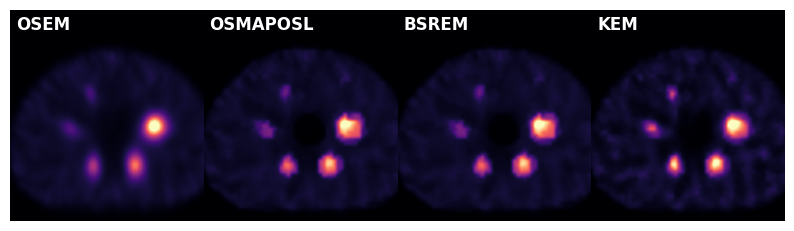

In [15]:
fig, ax = plt.subplots(1,4,figsize=(10,3), gridspec_kw={'wspace':0.0})
for i in range(4):
    plt.sca(ax[i])
    plt.imshow(recons[i][:,:,IDX_AXIAL].cpu().T , cmap='magma', interpolation='gaussian', origin='lower', vmax=20)
    plt.text(0.03, 0.97, recon_names[i], color='white', fontsize=12, fontweight='bold', transform=plt.gca().transAxes, ha='left', va='top')
    plt.xlim(35,90)
    plt.ylim(95,35)
    plt.axis('off')
plt.show()

## Save the images

`io.save_dicom` writes each reconstruction as a DICOM nuclear medicine (NM) file, placed by `object_meta`. The DICOM data's images are in their place in the patient, and `reference=file_NM` gives them the patient and study of the projections, so DICOM viewers show them with the scan's CT; SIMIND data have no patient, so their images are centred on the scanner's axis.

In [16]:
for name, recon in zip(recon_names, recons):
    io.save_dicom(recon, OUTPUT / 't_algorithms' / name, object_meta, reference=file_NM if TYPE == 'DICOM' else None,
                  units='counts', series_description=name, overwrite=True)